In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### other libraries
import finufft

### my modules
from fast_volume_align_ot import utils, plots, transforms

In [2]:
def zero_pad_voxel_array_to_size(f, L):
    pass

(67, 67, 67)


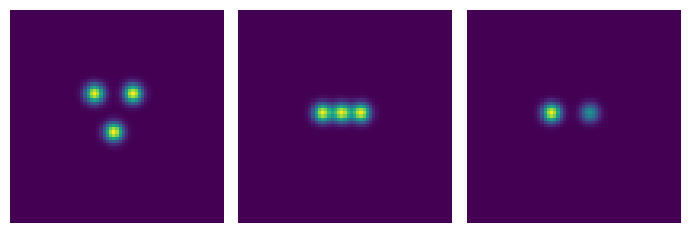

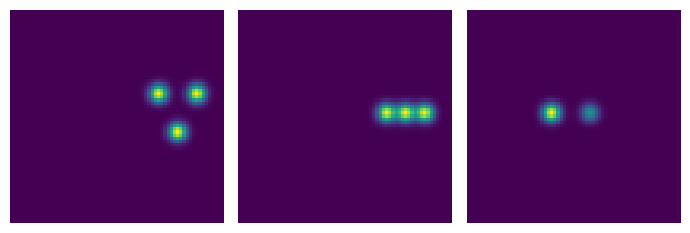

In [3]:
### generate initial volume
L = 37
sigma = 2
f = utils.generate_3d_triangle_gaussian_shape(L, sigma)
# f = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)

### zero pad to allow for shifting
w = 15
f = np.pad(f, pad_width=((w, w), (w, w), (w, w)))
print(f.shape)

plots.orthogonal_2D_projection_plot(f)

f_shift = utils.translate(f, 0, 0, 20)
plots.orthogonal_2D_projection_plot(f_shift)

In [9]:
# plt.imshow(f.sum(axis=0))
# plt.show()
# plt.imshow(f_shift.sum(axis=0))
# plt.show()
# plt.imshow(f.sum(axis=0) - f_shift.sum(axis=0))
# plt.show()

In [4]:
n_shifts = 20
shifts = np.arange(n_shifts+1)

dists_l2 = np.zeros(n_shifts+1)
dists_sw = np.zeros(n_shifts+1)

t = time.time()
F = transforms.compute_projection_tensor_from_voxel_array(f)
F_cdf = transforms.pdf_tensor_to_cdf_tensor(F)
U = transforms.cdf_tensor_to_icdf_tensor(F_cdf)
print('transform time: ', time.time() - t)

for idx, s in enumerate(shifts):
    
    f_shift = utils.translate(f, 0, 0, s)

    G = transforms.compute_projection_tensor_from_voxel_array(f_shift)
    G_cdf = transforms.pdf_tensor_to_cdf_tensor(G)
    V = transforms.cdf_tensor_to_icdf_tensor(G_cdf)
    
    ### EV: I think I'm missing some normalizing constants here ???
    d_sw = np.mean((U - V)**2)
    dists_sw[idx] = d_sw

    dists_l2[idx] = np.linalg.norm(f - f_shift)**2

transform time:  0.2610907554626465


In [5]:
dists_sw_normalized = np.sqrt(dists_sw / np.amax(dists_sw))
dists_l2_normalized = np.sqrt(dists_l2 / np.amax(dists_l2))

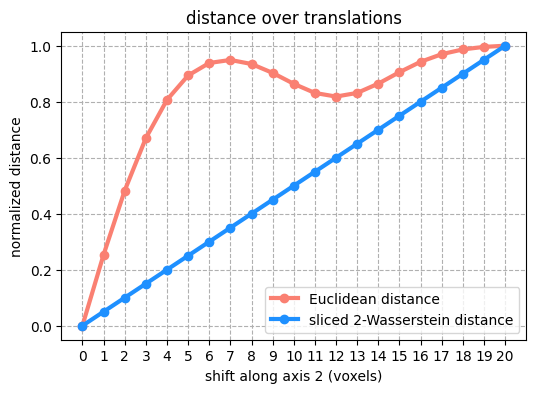

In [14]:
plt.figure(figsize=(6,4))

plt.plot(shifts, dists_l2_normalized, label='Euclidean distance', color='salmon', linewidth=3, linestyle='-', marker='o')
plt.plot(shifts, dists_sw_normalized, label='sliced 2-Wasserstein distance', color='dodgerblue', linewidth=3, linestyle='-', marker='o')

plt.xticks(shifts)
plt.grid(which='major', linestyle='--')
plt.xlabel('shift along axis 2 (voxels)')
plt.ylabel('normalized distance')
plt.title('distance over translations')
plt.legend()
plt.show()